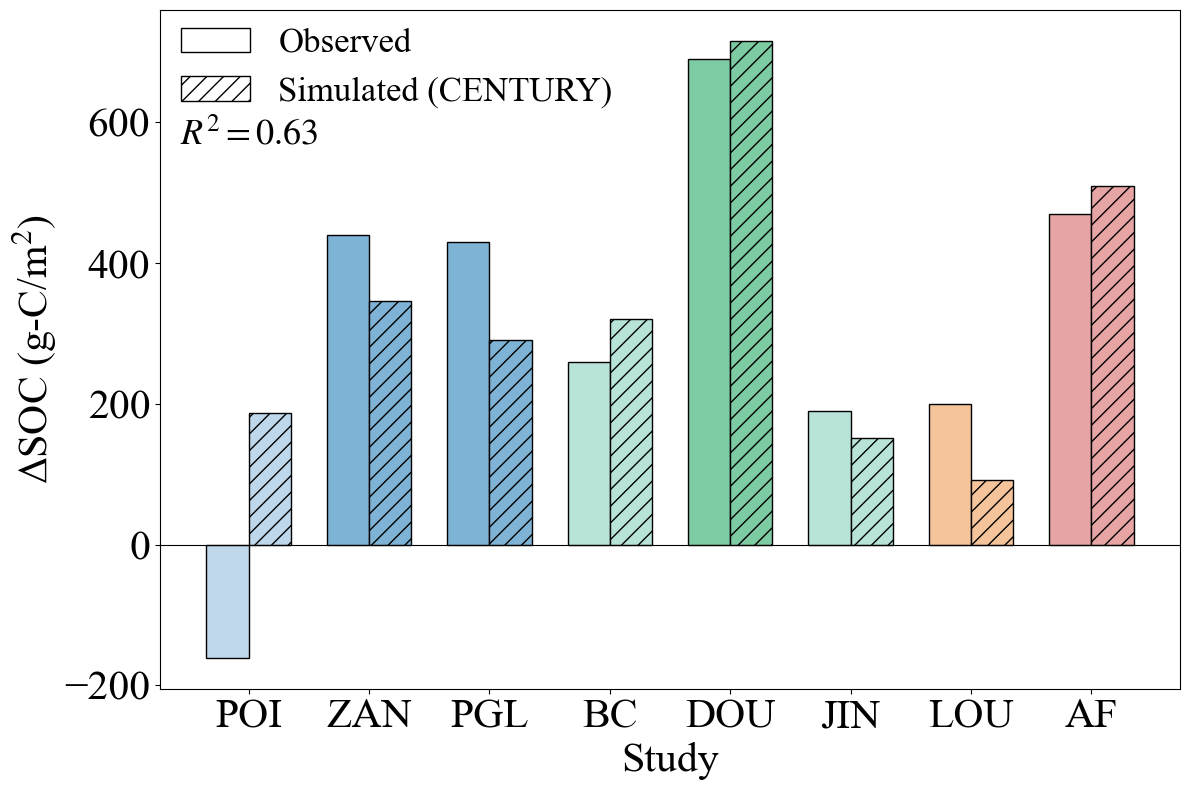

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import os
from matplotlib.patches import Patch
from IPython.display import display

mpl.rcParams['font.family'] = 'Times New Roman'
mpl.rcParams['mathtext.fontset'] = 'stix'

folder_path = r'C:\Users\rishabh.singh\OneDrive - Texas A&M AgriLife\Desktop\Slope\Results'
obs_excel = os.path.join(folder_path, "gcb15001-sup-0001-tables1.xlsx")

study_colors = {
    "AF":  "#E6A4A4",
    "BC":  "#B8E3D8",
    "DOU": "#7CCBA2",
    "JIN": "#B8E3D8",
    "LOU": "#F6C49B",
    "POI": "#BFD7EA",
    "PGL": "#7FB3D5",
    "ZAN": "#7FB3D5"
}

custom_order = ['POI', 'ZAN', 'PGL', 'BC', 'DOU', 'JIN', 'LOU', 'AF']
POOL_UNIFORM_COLOR = "#D9CECC"

def get_windows(df, duration, study):
    study = str(study).upper().strip()

    # Treat LOU same as POI
    if study in {"POI", "LOU"}:
        ct_start, ct_end = 1940, 1990
        nt_year = 2000 + int(duration)
    else:
        ct_start, ct_end = 785, 795
        nt_year = 800 + int(duration)

    ct_window = df.loc[
        (df.index >= ct_start) & (df.index <= ct_end),
        ['ACTIVE', 'SLOW', 'PASSIVE', 'SOC']
    ]
    return ct_window, nt_year

# Read Observations (duration + observed ΔSOC)
obs_df = pd.read_excel(obs_excel, sheet_name="SOC")
obs_df.columns = obs_df.columns.str.strip()
obs_df['Study'] = obs_df['Study'].astype(str).str.strip().str.upper()
obs_df = obs_df.set_index('Study')

obs_full = pd.read_excel(obs_excel, sheet_name="SOC")
obs_full.columns = obs_full.columns.str.strip()
obs_full['Study'] = obs_full['Study'].astype(str).str.strip().str.upper()

# ----- ΔSOC observed vs simulated -----
merged_df = pd.merge(
    sim_df,
    obs_full[["Study", "Observed Delta SOC"]],
    on="Study",
    how="inner"
)

merged_df['Study'] = merged_df['Study'].astype(str).str.strip().str.upper()
merged_df['Study'] = pd.Categorical(merged_df['Study'], categories=custom_order, ordered=True)
merged_df = merged_df.sort_values("Study").reset_index(drop=True)

def plot_obs_vs_sim_study_color(dfp, sim_col, obs_col, ylabel,
                                study_colors, bar_width=0.35,
                                fig_size=(12, 8),
                                sim_hatch='//',
                                legend_fontsize=25,
                                label_fontsize=30,
                                tick_fontsize=30,
                                r2_fontsize=26):

    dfp = dfp.copy()
    dfp['Study'] = dfp['Study'].astype(str).str.strip().str.upper()

    x_obs = pd.to_numeric(dfp[obs_col], errors="coerce").to_numpy(dtype=float)
    y_sim = pd.to_numeric(dfp[sim_col], errors="coerce").to_numpy(dtype=float)
    mask = np.isfinite(x_obs) & np.isfinite(y_sim)

    if mask.sum() >= 2:
        r2 = np.corrcoef(x_obs[mask], y_sim[mask])[0, 1] ** 2
        r2_text = rf"$R^2 = {r2:.2f}$"
    else:
        r2_text = r"$R^2 = \mathrm{NA}$"

    x = np.arange(len(dfp))
    fig, ax = plt.subplots(figsize=fig_size)

    for i, row in dfp.iterrows():
        study = str(row['Study'])
        color = study_colors.get(study, "#cccccc")

        ax.bar(x[i] - bar_width/2, row[obs_col], bar_width,
               color=color, edgecolor='black')
        ax.bar(x[i] + bar_width/2, row[sim_col], bar_width,
               color=color, edgecolor='black', hatch=sim_hatch)

    ax.set_xlabel("Study", fontsize=label_fontsize)
    ax.set_ylabel(ylabel, fontsize=label_fontsize)
    ax.set_xticks(x)
    ax.set_xticklabels(dfp['Study'], fontsize=tick_fontsize)
    ax.tick_params(axis='y', labelsize=tick_fontsize)
    ax.axhline(0, color='black', linewidth=0.8)

    legend_handles = [
        Patch(facecolor='white', edgecolor='black', label='Observed'),
        Patch(facecolor='white', edgecolor='black', hatch=sim_hatch, label='Simulated (CENTURY)')
    ]
    ax.legend(handles=legend_handles, fontsize=legend_fontsize, frameon=False,
              loc='upper left', bbox_to_anchor=(-0.01, 1.02))

    ax.text(0.02, 0.84, r2_text,
            transform=ax.transAxes,
            ha='left', va='top',
            fontsize=r2_fontsize,
            fontfamily='Times New Roman')

    plt.tight_layout()
    return fig

fig_soc = plot_obs_vs_sim_study_color(
    merged_df,
    sim_col="Simulated Delta SOC",
    obs_col="Observed Delta SOC",
    ylabel="ΔSOC (g-C/m$^2$)",
    study_colors=study_colors
)

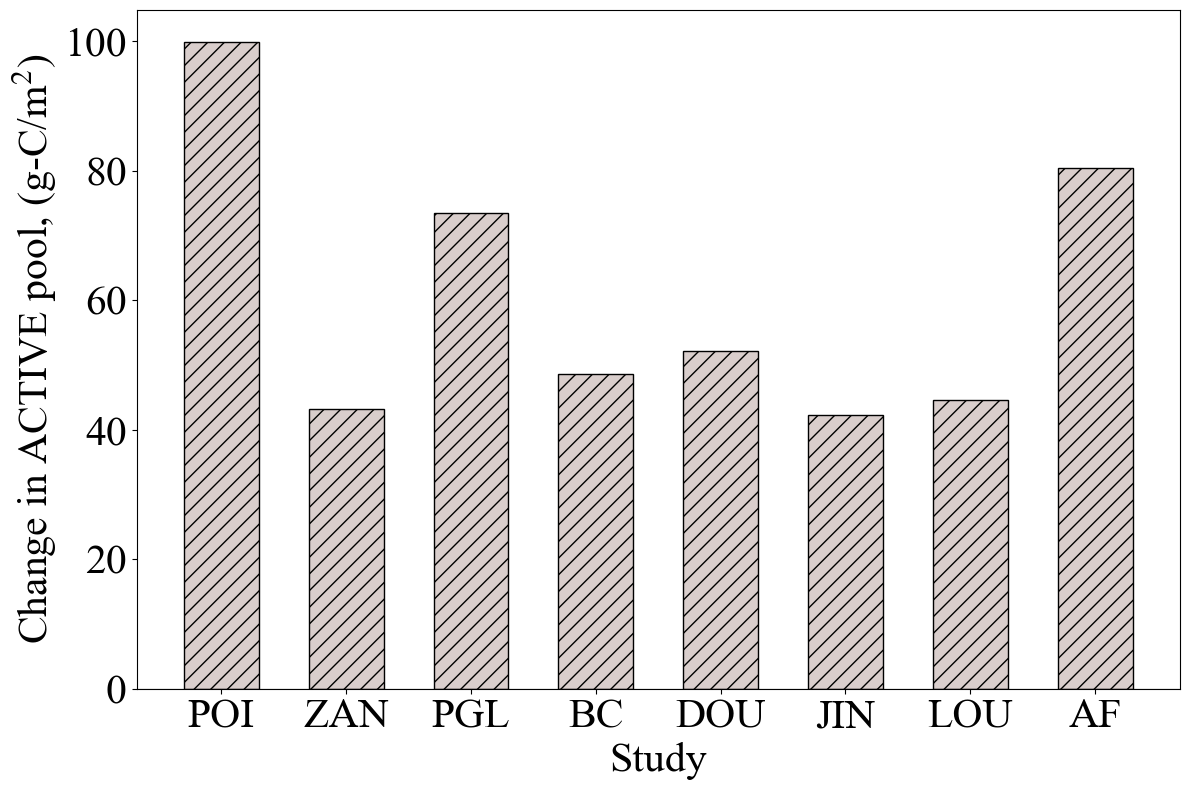

In [3]:
# =========================
# Plot ΔACTIVE (Simulated only)
# =========================
def plot_sim_delta_single(dfp, delta_col, ylabel,
                          uniform_color=POOL_UNIFORM_COLOR,
                          fig_size=(12, 8),
                          label_fontsize=30,
                          tick_fontsize=30,
                          bar_width=0.6,          # narrower bars
                          hatch_style='//'):      # hatch style

    dfp = dfp.copy()
    dfp['Study'] = dfp['Study'].astype(str).str.strip().str.upper()

    x = np.arange(len(dfp))
    fig, ax = plt.subplots(figsize=fig_size)

    ax.bar(
        x,
        dfp[delta_col].astype(float),
        width=bar_width,
        color=uniform_color,
        edgecolor='black',
        hatch=hatch_style
    )

    ax.set_xlabel("Study", fontsize=label_fontsize)
    ax.set_ylabel(ylabel, fontsize=label_fontsize)
    ax.set_xticks(x)
    ax.set_xticklabels(dfp['Study'], fontsize=tick_fontsize)
    ax.tick_params(axis='y', labelsize=tick_fontsize)
    ax.axhline(0, color='black', linewidth=0.8)

    plt.tight_layout()
    return fig


sim_delta_df = pool_df[["Study", "DELTA_ACTIVE"]].copy()
sim_delta_df["Study"] = sim_delta_df["Study"].astype(str).str.strip().str.upper()
sim_delta_df["Study"] = pd.Categorical(sim_delta_df["Study"], categories=custom_order, ordered=True)
sim_delta_df = sim_delta_df.sort_values("Study").reset_index(drop=True)

fig_active = plot_sim_delta_single(
    sim_delta_df,
    "DELTA_ACTIVE",
    ylabel="Change in ACTIVE pool, (g-C/m$^2$)"
)

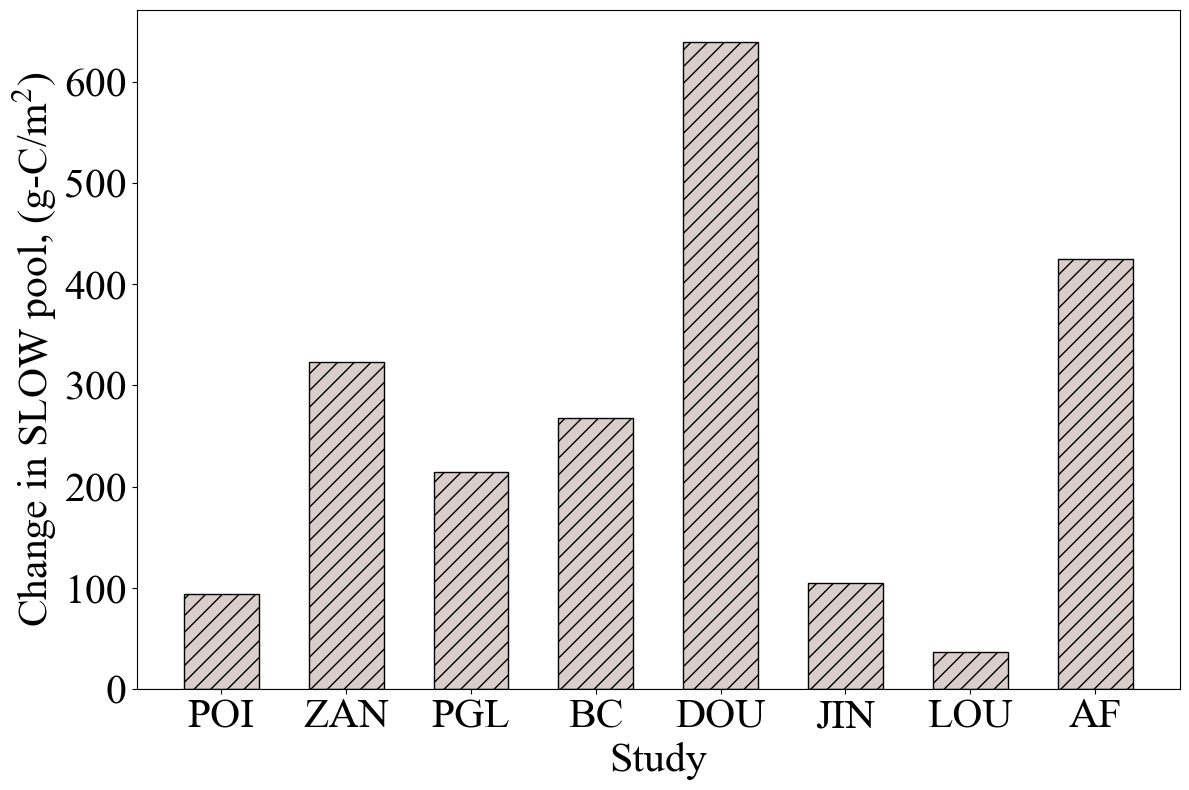

In [4]:
# =========================
# Plot ΔSLOW (Simulated only)
# =========================
def plot_sim_delta_single(dfp, delta_col, ylabel,
                          uniform_color=POOL_UNIFORM_COLOR,
                          fig_size=(12, 8),
                          label_fontsize=30,
                          tick_fontsize=30,
                          bar_width=0.6,
                          hatch_style='//'):

    dfp = dfp.copy()
    dfp['Study'] = dfp['Study'].astype(str).str.strip().str.upper()

    x = np.arange(len(dfp))
    fig, ax = plt.subplots(figsize=fig_size)

    ax.bar(
        x,
        dfp[delta_col].astype(float),
        width=bar_width,
        color=uniform_color,
        edgecolor='black',
        hatch=hatch_style
    )

    ax.set_xlabel("Study", fontsize=label_fontsize)
    ax.set_ylabel(ylabel, fontsize=label_fontsize)
    ax.set_xticks(x)
    ax.set_xticklabels(dfp['Study'], fontsize=tick_fontsize)
    ax.tick_params(axis='y', labelsize=tick_fontsize)
    ax.axhline(0, color='black', linewidth=0.8)

    plt.tight_layout()
    return fig


sim_delta_df = pool_df[["Study", "DELTA_SLOW"]].copy()
sim_delta_df["Study"] = sim_delta_df["Study"].astype(str).str.strip().str.upper()
sim_delta_df["Study"] = pd.Categorical(sim_delta_df["Study"], categories=custom_order, ordered=True)
sim_delta_df = sim_delta_df.sort_values("Study").reset_index(drop=True)

fig_slow = plot_sim_delta_single(
    sim_delta_df,
    "DELTA_SLOW",
    ylabel="Change in SLOW pool, (g-C/m$^2$)"
)

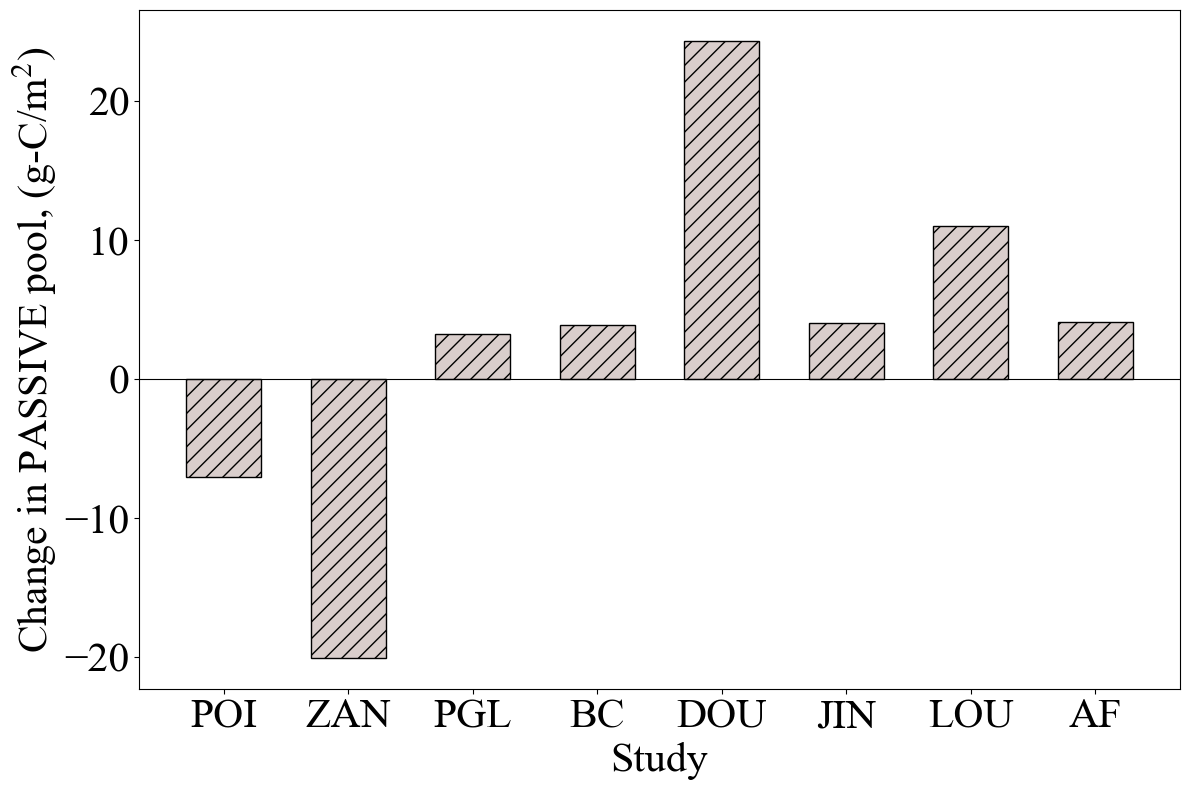

In [5]:
# =========================
# Plot ΔPASSIVE (Simulated only)
# =========================
def plot_sim_delta_single(dfp, delta_col, ylabel,
                          uniform_color=POOL_UNIFORM_COLOR,
                          fig_size=(12, 8),
                          label_fontsize=30,
                          tick_fontsize=30,
                          bar_width=0.6,
                          hatch_style='//'):

    dfp = dfp.copy()
    dfp['Study'] = dfp['Study'].astype(str).str.strip().str.upper()

    x = np.arange(len(dfp))
    fig, ax = plt.subplots(figsize=fig_size)

    ax.bar(
        x,
        dfp[delta_col].astype(float),
        width=bar_width,
        color=uniform_color,
        edgecolor='black',
        hatch=hatch_style
    )

    ax.set_xlabel("Study", fontsize=label_fontsize)
    ax.set_ylabel(ylabel, fontsize=label_fontsize)
    ax.set_xticks(x)
    ax.set_xticklabels(dfp['Study'], fontsize=tick_fontsize)
    ax.tick_params(axis='y', labelsize=tick_fontsize)
    ax.axhline(0, color='black', linewidth=0.8)

    plt.tight_layout()
    return fig


sim_delta_df = pool_df[["Study", "DELTA_PASSIVE"]].copy()
sim_delta_df["Study"] = sim_delta_df["Study"].astype(str).str.strip().str.upper()
sim_delta_df["Study"] = pd.Categorical(sim_delta_df["Study"], categories=custom_order, ordered=True)
sim_delta_df = sim_delta_df.sort_values("Study").reset_index(drop=True)

fig_passive = plot_sim_delta_single(
    sim_delta_df,
    "DELTA_PASSIVE",
    ylabel="Change in PASSIVE pool, (g-C/m$^2$)"
)